# Hedge Ratios in Quantitative Finance — A Practical Study Notebook

**From first principles to multi-asset hedging | Beginner → intermediate | Simulated data only**

This notebook teaches **what to compare**, **why hedge ratios work**, **how to calculate them**, and **how to test them** for: equity/index futures, interest-rate futures versus bonds, government bonds and swaps (DV01), foreign exchange, options (delta), pairs trading, and commodities.

**Special case:** A futures portfolio with **end-of-day (EOD) P&L** hedged using a bond with **EOD prices**. We build a carefully unit-normalised hedge and compare it with DV01 hedging.

### Roadmap
1. Setup, units and data conventions
2. Variance, covariance, correlation and the optimal hedge
3. Equity portfolio vs index futures
4. **Futures portfolio EOD P&L vs bond EOD price** (deep dive)
5. Bond / interest-rate DV01 and key-rate hedges
6. FX exposure hedge
7. Option delta hedge and dynamic rebalancing
8. Pairs trading hedge coefficient
9. Commodity futures cross-hedge
10. Multi-instrument regression, backtesting, pitfalls and exercises

> **Educational simulation, not trading advice.** Numbers are invented and market mechanics simplified. All simulations use deterministic random seeds so plots are reproducible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display

rng = np.random.default_rng(20261020)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .25})
N = 500
dates = pd.bdate_range('2024-01-02', periods=N)

def ols_slope(y, x):
    """Slope in y = intercept + slope*x; arrays must be aligned and in consistent units."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    return np.cov(y, x, ddof=1)[0,1] / np.var(x, ddof=1)

def report(label, unhedged, hedged):
    u, h = np.asarray(unhedged), np.asarray(hedged)
    reduction = 1 - np.var(h, ddof=1)/np.var(u, ddof=1)
    print(f'{label}: unhedged daily vol={np.std(u,ddof=1):,.2f}, '
          f'hedged daily vol={np.std(h,ddof=1):,.2f}, variance reduction={reduction:.1%}')
    return reduction

def pnl_plot(index, base, hedged, title, ylabel='Cumulative P&L (£)'):
    plt.figure(figsize=(10,4))
    plt.plot(index, np.cumsum(base), label='Unhedged', lw=1.5)
    plt.plot(index, np.cumsum(hedged), label='Hedged', lw=1.5)
    plt.title(title); plt.ylabel(ylabel); plt.legend(); plt.tight_layout(); plt.show()

print('Ready: numpy, pandas, matplotlib, scipy; simulated', N, 'business days.')

Ready: numpy, pandas, matplotlib, scipy; simulated 500 business days.


## 1. Units first: what are we measuring?

A **hedge** is a second position intended to reduce fluctuations of an existing position. The **hedge ratio** indicates the size of that second position.

| Quantity | Interpretation | Example unit |
|---|---|---|
| EOD price \(B_t\) | Security value at a date | bond price points per £100 face |
| Price change \(\Delta B_t\) | Today's price minus yesterday's | price points |
| Daily P&L \(Y_t\) | Gain or loss **over the same interval** | £/day |
| Hedge-unit P&L \(X_t\) | P&L for one bond unit or fixed £1m face | £/day per £1m face |
| Position \(q\) | Quantity to buy (positive) or sell (negative) | blocks of £1m face |

We choose \(q\) to minimise the volatility of \(Y_t+qX_t\). **Never regress P&L on raw price levels**: a level is not a daily gain. Convert price changes into monetary P&L before sizing, then align dates, currencies, settlement conventions, and cash flows.

**Sign convention throughout:** a positive position is **long**. Thus \(q>0\) buys the hedge instrument; \(q<0\) shorts it. No-hedge P&L is \(Y\); hedged P&L is \(Y+qX\).

**Bond price quotation:** if a price is 98.20 per £100 face and face amount is £1,000,000, market value is approximately \(98.20/100\times£1,000,000\), before accrued interest. For daily *total* economic P&L include coupon/accrual/carry; the following examples first isolate clean-price changes to make the mechanics visible.

## 2. Derive the minimum-variance hedge ratio

Let \(Y\) be the daily P&L of the exposure and \(X\) the daily P&L of **one hedge unit**. Your combined daily P&L is:

\[
H(q)=Y+qX.
\]

Using the variance identity:

\[
\operatorname{Var}(H(q))=\operatorname{Var}(Y)+2q\operatorname{Cov}(Y,X)+q^2\operatorname{Var}(X).
\]

Differentiate with respect to \(q\), set the result to zero:

\[
2\operatorname{Cov}(Y,X)+2q\operatorname{Var}(X)=0
\quad\Longrightarrow\quad
\boxed{q^*=-\frac{\operatorname{Cov}(Y,X)}{\operatorname{Var}(X)}}.
\]

**Why correlation matters:** \(\operatorname{Cov}(Y,X)=\rho_{Y,X}\sigma_Y\sigma_X\), so \(q^*=-\rho_{Y,X}\sigma_Y/\sigma_X\). This is **minus the OLS slope** when regressing \(Y\) on \(X\) with an intercept. The minus sign implements offsetting positions; a *positive* slope requires a *short* hedge.

For this in-sample single-instrument setup with an intercept, the reduction in variance is \(\rho^2\). It does **not** guarantee a reduction in worst losses, nor does it predict out-of-sample hedge quality.

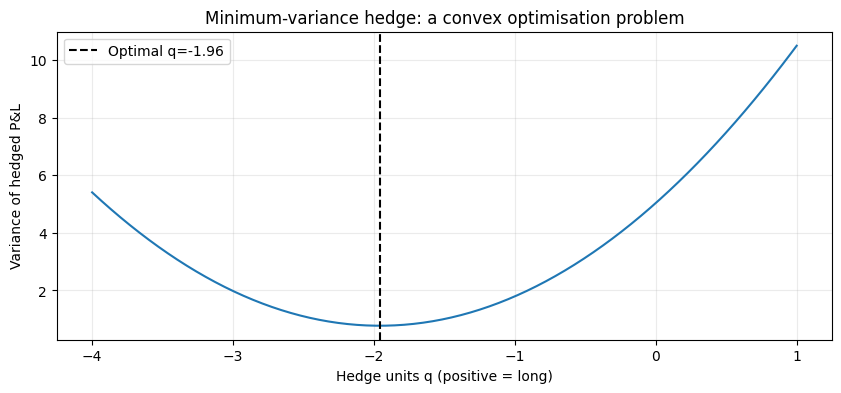

OLS slope: 1.958; required hedge position: -1.958
Toy hedge: unhedged daily vol=2.24, hedged daily vol=0.88, variance reduction=84.6%


np.float64(0.8460091970274184)

In [2]:
# Visualise why there is an optimal hedge size
x = rng.normal(0, 1, N)                 # one hedge unit's P&L
y = 2.0*x + rng.normal(0, 0.9, N)       # exposed P&L
qstar = -ols_slope(y, x)
qs = np.linspace(-4, 1, 150)
variances = [np.var(y + q*x, ddof=1) for q in qs]
plt.plot(qs, variances)
plt.axvline(qstar, color='black', ls='--', label=f'Optimal q={qstar:.2f}')
plt.xlabel('Hedge units q (positive = long)'); plt.ylabel('Variance of hedged P&L')
plt.title('Minimum-variance hedge: a convex optimisation problem'); plt.legend(); plt.show()
print(f'OLS slope: {ols_slope(y,x):.3f}; required hedge position: {qstar:.3f}')
report('Toy hedge', y, y + qstar*x)

## 3. Equities versus index futures

An equity portfolio is often hedged by shorting index futures. If you work with **daily returns**, a familiar approximation is:

\[
\beta=\frac{\operatorname{Cov}(r_p,r_f)}{\operatorname{Var}(r_f)},\qquad
N_f\approx-\beta\frac{V_p}{F_tM}
\]

where \(V_p\) = portfolio value, \(F_t\) = futures index level, \(M\) = contract multiplier in currency per index point. This gives **number of contracts**, not a dimensionless hedge coefficient. The example ignores funding, margins, tracking error and contract rolls.

Beta=1.120; futures contract notional=£50,000; ideal contracts=-179.2 (real executions require whole contracts)
Equity/index futures: unhedged daily vol=104,215.69, hedged daily vol=35,824.05, variance reduction=88.2%


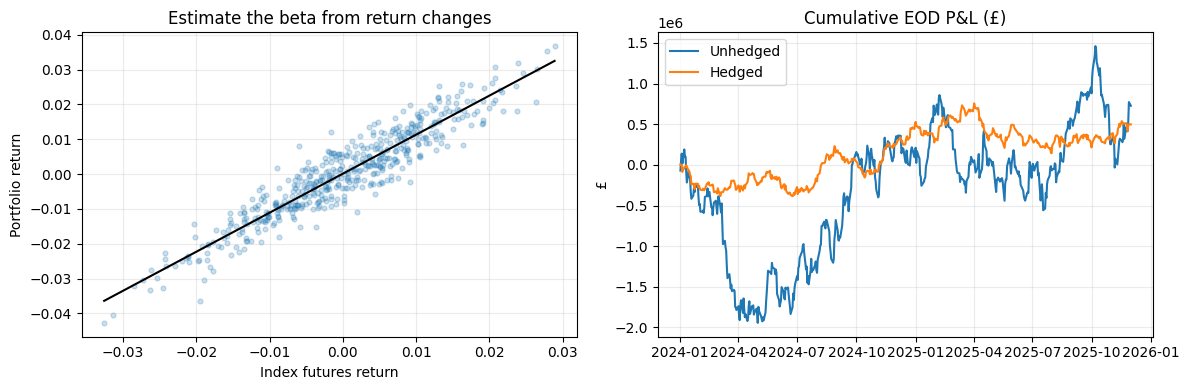

In [3]:
# Two correlated return series; equity exposure with idiosyncratic risk
rf = rng.normal(.00025, .011, N)
rp = .00015 + 1.13*rf + rng.normal(0, .0045, N)
portfolio_value = 8_000_000  # £
index_level, contract_multiplier = 5_000, 10  # £ per index point
beta = ols_slope(rp, rf)
contracts = -beta * portfolio_value / (index_level * contract_multiplier)
futures_unit_pnl = index_level * contract_multiplier * rf
portfolio_pnl = portfolio_value * rp
hedged_eq = portfolio_pnl + contracts*futures_unit_pnl
print(f'Beta={beta:.3f}; futures contract notional=£{index_level*contract_multiplier:,.0f}; '
      f'ideal contracts={contracts:.1f} (real executions require whole contracts)')
report('Equity/index futures', portfolio_pnl, hedged_eq)
fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].scatter(rf, rp, alpha=.23, s=12); xx=np.linspace(rf.min(), rf.max(),50)
ax[0].plot(xx, np.mean(rp)+beta*(xx-np.mean(rf)),color='black')
ax[0].set(xlabel='Index futures return',ylabel='Portfolio return',title='Estimate the beta from return changes')
ax[1].plot(dates,np.cumsum(portfolio_pnl),label='Unhedged');ax[1].plot(dates,np.cumsum(hedged_eq),label='Hedged')
ax[1].set(title='Cumulative EOD P&L (£)',ylabel='£');ax[1].legend();plt.tight_layout();plt.show()

## 4. Deep dive: Futures portfolio EOD P&L hedged with one bond's EOD prices

### Exactly what to compare

- **Target:** daily futures *portfolio* P&L, \(Y_t\), in £ for the period from yesterday's close to today's close. Separate trading/rebalancing P&L if possible.
- **Hedge:** the bond's EOD **clean** or **dirty** prices, transformed into daily changes \(\Delta B_t=B_t-B_{t-1}\); convert those changes to £ P&L of **one fixed bond-face block**.
- **Dates:** match today's futures P&L with the bond price change **ending today**; avoid comparing today's P&L to tomorrow's price changes (look-ahead bias).
- **Currency:** translate consistently if the futures P&L and bond are denominated differently.

For £1 million of bond face and a price quoted **per £100 face**:

\[
X_t = \frac{1{,}000{,}000}{100}(B_t-B_{t-1})
\quad\text{[£ P&L per £1m face]}.
\]

If \(q\) is measured in **£1m face blocks**:

\[
q^*=-\frac{\operatorname{Cov}(Y,X)}{\operatorname{Var}(X)},\qquad
\text{bond face to trade}=q^*\times£1{,}000{,}000.
\]

The result is **statistical risk minimisation**, not necessarily interest-rate neutrality. A futures portfolio can contain basis, convexity and curve risk that one bond cannot offset.

,Bond clean price,Bond price change,Bond £ P&L / £1m face,Futures book EOD P&L (£)
2024-01-02,98.02,0.02,215.41,364.59
2024-01-03,98.14,0.12,1215.28,-11827.30
2024-01-04,98.14,0.00,17.38,1964.89
2024-01-05,98.05,-0.09,-942.30,9039.52
2024-01-08,98.01,-0.04,-440.11,12828.12
2024-01-09,98.13,0.12,1240.79,-11149.77


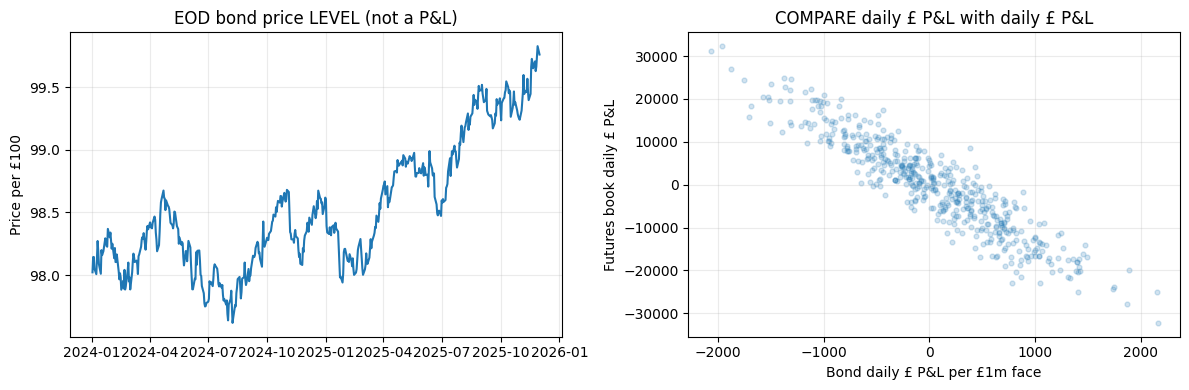

In [4]:
# Synthesize a bond price level and a futures book whose DAILY P&L loads on bond movements.
# A random walk approximates a tradable price level, but returns/P&L should be modelled,
# not regressions on the price level.
DB = rng.normal(0.002, 0.075, N)          # daily clean-price changes per £100 face
bond_price = 98 + np.cumsum(DB)            # end-of-day bond clean-price series
bond_pnl_per_million = 1_000_000 / 100 * DB  # £ daily P&L per £1m bond face
true_loading = -14.0                      # futures book behaves ~short 14 x bond £1m blocks
futures_book_pnl = (true_loading * bond_pnl_per_million
                    + rng.normal(0, 4200, N) + 120)
frame = pd.DataFrame({'Bond clean price': bond_price,
                      'Bond price change': DB,
                      'Bond £ P&L / £1m face': bond_pnl_per_million,
                      'Futures book EOD P&L (£)': futures_book_pnl}, index=dates)
display(frame.head(6).round(2))
fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(frame.index,frame['Bond clean price']);ax[0].set(title='EOD bond price LEVEL (not a P&L)',ylabel='Price per £100')
ax[1].scatter(frame['Bond £ P&L / £1m face'],futures_book_pnl,alpha=.2,s=12)
ax[1].set(title='COMPARE daily £ P&L with daily £ P&L',xlabel='Bond daily £ P&L per £1m face',ylabel='Futures book daily £ P&L')
plt.tight_layout();plt.show()

Estimated book sensitivity to £1m bond face: -14.060
Optimal bond hedge: +14.060 blocks of £1m face, i.e. +14,060,350 GBP face (positive=BUY, negative=SELL)
Correlation: -0.928
EOD book/bond (in sample): unhedged daily vol=10,930.13, hedged daily vol=4,082.79, variance reduction=86.0%


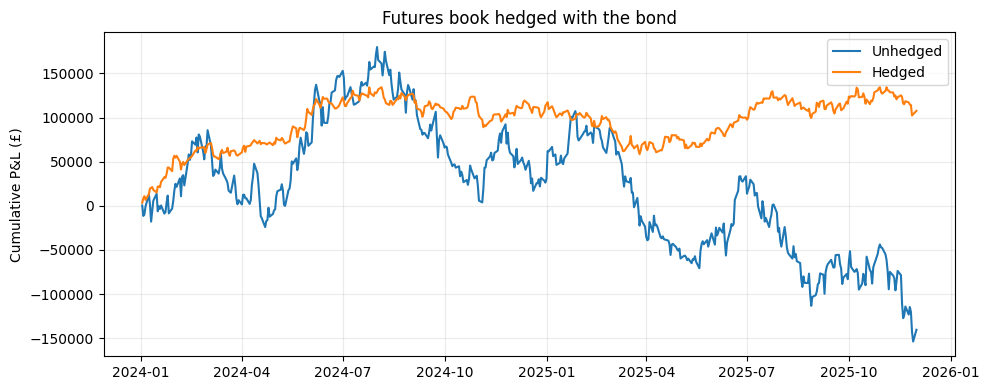

In [5]:
# Same-date close-to-close changes; covariance and OLS are equivalent.
x_b = frame['Bond £ P&L / £1m face'].to_numpy()
y_f = frame['Futures book EOD P&L (£)'].to_numpy()
loading = ols_slope(y_f, x_b)
q_bond = -loading
hedged_bond = y_f + q_bond*x_b
print(f'Estimated book sensitivity to £1m bond face: {loading:.3f}')
print(f'Optimal bond hedge: {q_bond:+.3f} blocks of £1m face, '
      f'i.e. {q_bond*1_000_000:+,.0f} GBP face (positive=BUY, negative=SELL)')
print(f'Correlation: {np.corrcoef(y_f, x_b)[0,1]:.3f}')
report('EOD book/bond (in sample)', y_f, hedged_bond)
pnl_plot(dates,y_f,hedged_bond,'Futures book hedged with the bond')

### Important accounting caveats

A bond **clean-price change** excludes changes in accrued interest and coupon cash flows. For production risk/P&L explain use **dirty-price/total-return P&L including accrued interest and coupon**, adjusted for any buys/sells, financing and FX. For futures include variation margin mark-to-market, contract multiplier, roll P&L and positions over the actual interval. Be consistent about **which position produced the observed P&L**. Old portfolio holdings may need to be normalised for position-size changes before a hedge is portable.

If the price series comes from EOD marks, check for stale marks, different market-close times, holiday misalignment, missing days, interpolation artefacts and outliers. A missing day's price should **not** generally be filled with a fabricated zero daily return.

### From regression to actual positions: train/test split

Estimating the hedge on *all* days and then reporting performance on those *same* days exaggerates practical confidence. Freeze the position estimated on the **first 70%** of days and test on the remaining unseen 30%.

Hedge estimated from training data: +13.76 £1m face blocks
Training: unhedged daily vol=10,760.66, hedged daily vol=4,115.54, variance reduction=85.4%
Unseen test: unhedged daily vol=11,347.69, hedged daily vol=4,037.91, variance reduction=87.3%


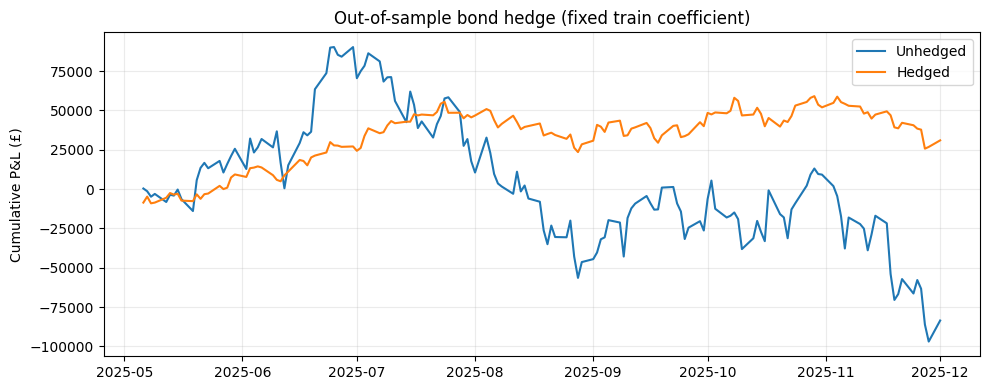

A +0.10 price-point move on £1m face implies P&L £ 1000.0


In [6]:
split = int(.7*N)
q_train = -ols_slope(y_f[:split], x_b[:split])
train_hedge = y_f[:split] + q_train*x_b[:split]
test_hedge = y_f[split:] + q_train*x_b[split:]
print(f'Hedge estimated from training data: {q_train:+.2f} £1m face blocks')
report('Training', y_f[:split], train_hedge)
report('Unseen test', y_f[split:], test_hedge)
pnl_plot(dates[split:],y_f[split:],test_hedge,'Out-of-sample bond hedge (fixed train coefficient)')
# Check the unit conversion with a simple daily move
print('A +0.10 price-point move on £1m face implies P&L £', 0.10/100*1_000_000)

## 5. Bond hedging: DV01 and the term structure

**DV01** is the approximate £ P&L for a **1 basis point (0.01 percentage point) fall in yield** (positive DV01 for a long conventional fixed-rate bond):

\[
\Delta P\approx-\mathrm{DV01}\times\Delta y_{\rm bp}.
\]

For a book with DV01 \(D_p\) and hedge bond DV01 \(D_b\) for a specified face unit:

\[
\boxed{q_{\rm DV01}=-D_p/D_b}.
\]

**Do not mix sign conventions:** some risk systems report \(dP/dy\) (negative for a long bond), whereas others report *gain for a 1bp yield fall* (positive). The examples use the latter.

Single DV01 assumes an approximately parallel yield shift. **Key-rate DV01** measures sensitivity at different tenors, e.g. 2y, 5y and 10y; one bond rarely offsets a complex curve exposure.

Hold -24.0 x £1m bond face (negative means SHORT) to neutralise DV01
DV01 hedge: unhedged daily vol=82,037.04, hedged daily vol=3,241.30, variance reduction=99.8%


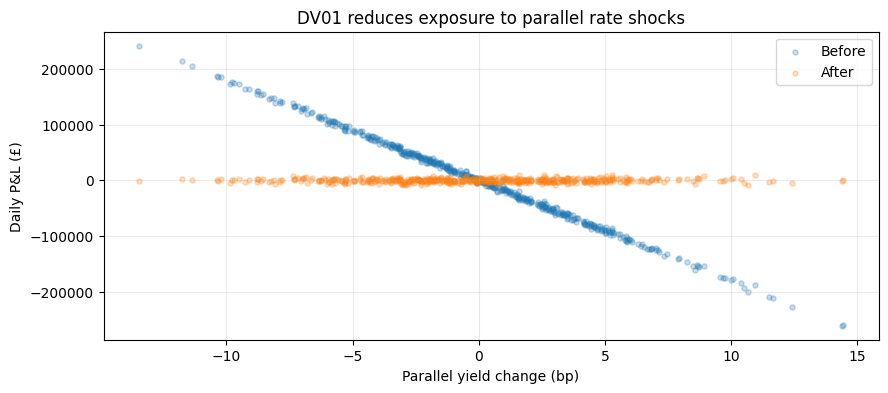

In [7]:
# Compare interest-rate risk using synthetic yield shocks in basis points
bp = rng.normal(0, 4.5, N)
book_dv01 = 18_000               # £ per bp: portfolio gain if yields FALL 1bp
bond_unit_dv01 = 750             # £ per bp for each £1m face (illustrative)
pnl_rate_book = -book_dv01 * bp + rng.normal(0, 3500, N)
pnl_rate_bond_unit = -bond_unit_dv01 * bp
q_dv01 = -book_dv01 / bond_unit_dv01
print(f'Hold {q_dv01:+.1f} x £1m bond face (negative means SHORT) to neutralise DV01')
report('DV01 hedge', pnl_rate_book, pnl_rate_book+q_dv01*pnl_rate_bond_unit)
plt.scatter(bp,pnl_rate_book,alpha=.25,s=14,label='Before')
plt.scatter(bp,pnl_rate_book+q_dv01*pnl_rate_bond_unit,alpha=.25,s=14,label='After')
plt.xlabel('Parallel yield change (bp)');plt.ylabel('Daily P&L (£)');plt.title('DV01 reduces exposure to parallel rate shocks')
plt.legend();plt.show()

Parallel-DV01 single 10y bond hedge: -16.19 x £1m face
Key-rate 2-bond hedge: 2y=-1.85 blocks, 10y=-14.81 blocks
Only parallel-DV01: unhedged daily vol=53,944.78, hedged daily vol=3,311.20, variance reduction=99.6%
2-key-rate neutral: unhedged daily vol=53,944.78, hedged daily vol=0.00, variance reduction=100.0%


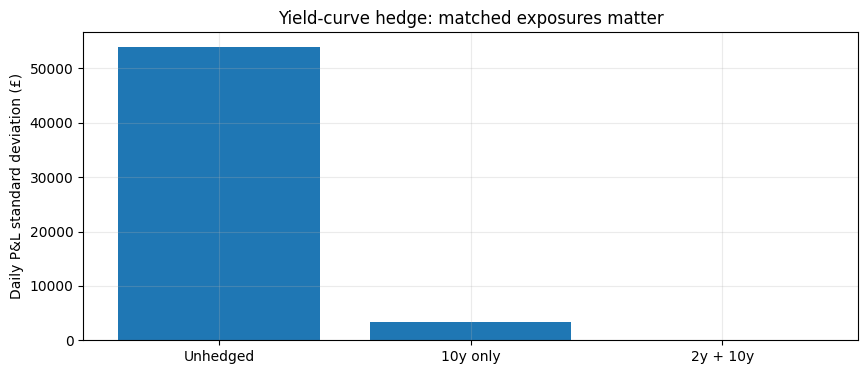

In [8]:
# A two-tenor example: one 10y bond cannot remove all 2y + 10y curve risk.
short_bp = rng.normal(0, 3.5, N)
long_bp = .50*short_bp + rng.normal(0, 3, N)
shocks = np.column_stack([short_bp, long_bp])
book_key_dv01 = np.array([5000., 12000.]) # £ per bp for 2y and 10y
bond_10y_key_dv01 = np.array([250., 800.])# per £1m 10y bond
bond_2y_key_dv01 = np.array([700., 80.])  # per £1m 2y bond
rate_book = -(shocks @ book_key_dv01)
# Solve vector hedge: d_book + [d_bond2 d_bond10] @ q = 0
K = np.column_stack([bond_2y_key_dv01,bond_10y_key_dv01])
q2 = np.linalg.solve(K,-book_key_dv01)
q_only_10y = -book_key_dv01.sum()/bond_10y_key_dv01.sum()
hedged_10y = rate_book - q_only_10y*(shocks@bond_10y_key_dv01)
hedged_2bond = rate_book - shocks@(K@q2)
print(f'Parallel-DV01 single 10y bond hedge: {q_only_10y:.2f} x £1m face')
print(f'Key-rate 2-bond hedge: 2y={q2[0]:.2f} blocks, 10y={q2[1]:.2f} blocks')
report('Only parallel-DV01', rate_book,hedged_10y)
report('2-key-rate neutral',rate_book,hedged_2bond)
plt.bar(['Unhedged','10y only','2y + 10y'],[np.std(a,ddof=1) for a in [rate_book,hedged_10y,hedged_2bond]])
plt.ylabel('Daily P&L standard deviation (£)');plt.title('Yield-curve hedge: matched exposures matter');plt.show()

## 6. FX forward hedge

A GBP-based investor holding USD assets can reduce GBP/USD exchange-rate risk using an FX forward. For a **linear USD receivable** of \(U\) dollars, selling \(U\) dollars forward approximately locks the conversion rate (subject to contract settlement and credit terms).

A naive hedge based solely on the amount of foreign currency differs from an **optimal statistical cross-hedge** where the exposure includes other risks. Below, compare changes in **GBP value per USD** (GBP/USD in *GBP per USD* units) and dollar exposure. Be careful: currency pairs invert depending on market quoting conventions.

FX delta hedge: unhedged daily vol=3,999.20, hedged daily vol=0.00, variance reduction=100.0%


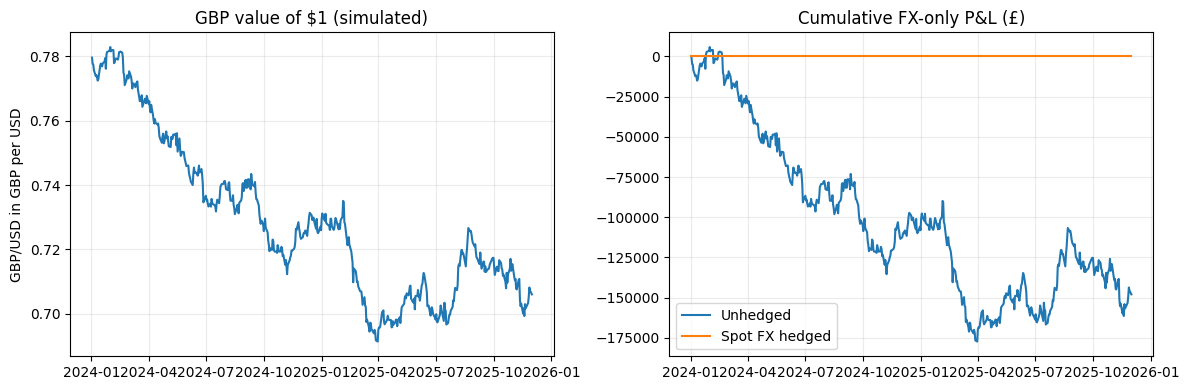

In [9]:
# S = GBP per USD; a GBP investor owns $2m, so delta GBP value = USD_exposure * delta S.
s = .78 + np.cumsum(rng.normal(0,.002,N))
ds = np.diff(np.r_[.78,s])
usd_exposure = 2_000_000
unhedged_fx = usd_exposure*ds
# Short $2m forward => opposite approximate spot-rate P&L (ignore forward-point carry)
short_usd_forward_pnl = -usd_exposure*ds
report('FX delta hedge',unhedged_fx,unhedged_fx+short_usd_forward_pnl)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(dates,s);ax[0].set(title='GBP value of $1 (simulated)',ylabel='GBP/USD in GBP per USD')
ax[1].plot(dates,np.cumsum(unhedged_fx),label='Unhedged');ax[1].plot(dates,np.cumsum(unhedged_fx+short_usd_forward_pnl),label='Spot FX hedged')
ax[1].set(title='Cumulative FX-only P&L (£)');ax[1].legend();plt.tight_layout();plt.show()

## 7. Options: delta hedge and why it changes

The **delta** \(\Delta=\partial V/\partial S\) approximates the option price change for a £1 move in the underlying. For \(n\) **long** calls with multiplier \(M\), a delta-neutral hedge shorts about \(nM\Delta\) shares.

For a European call in a simplified zero-dividend Black–Scholes setting:

\[
\Delta=N(d_1),\quad d_1=\frac{\ln(S/K)+(r+\tfrac12\sigma^2)T}{\sigma\sqrt T}.
\]

Unlike a fixed hedge, delta changes as the asset moves or time passes (**gamma** and **time decay**). Rebalancing reduces directional exposure but generates costs and does not remove gap risk. We simulate daily *mark-to-market* P&L: long call option P&L plus share hedge P&L, sized using **previous day's delta** (no look-ahead).

Daily dynamic delta hedge: unhedged daily vol=2,074.59, hedged daily vol=142.15, variance reduction=99.5%


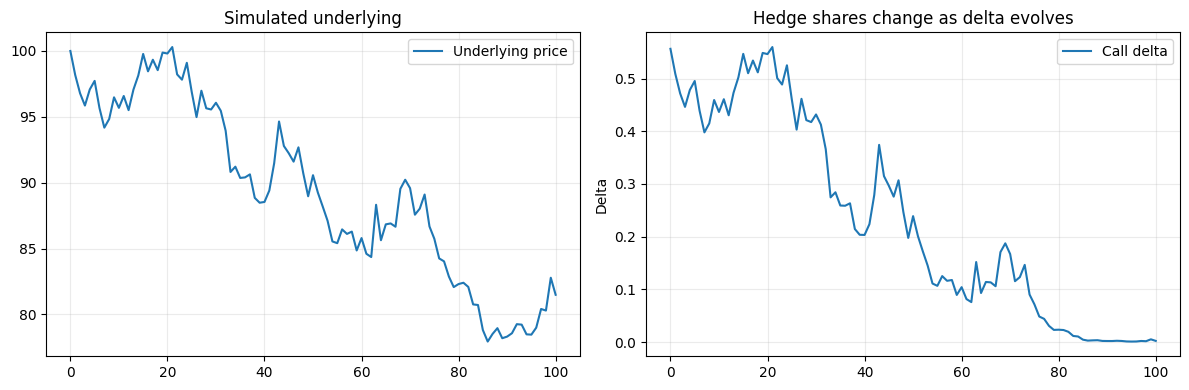

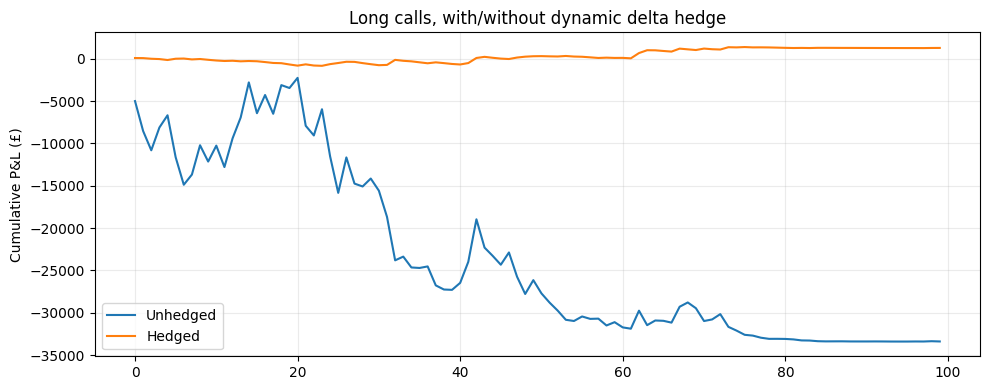

In [10]:
def bs_call_and_delta(S,K,T,r,sigma):
    T = max(float(T), 1e-8)
    d1=(np.log(S/K)+(r+.5*sigma*sigma)*T)/(sigma*np.sqrt(T))
    d2=d1-sigma*np.sqrt(T)
    return S*norm.cdf(d1)-K*np.exp(-r*T)*norm.cdf(d2), norm.cdf(d1)

S = np.empty(101); S[0]=100
for t in range(100): S[t+1]=S[t]*np.exp((.02-.5*.22**2)/252+.22/np.sqrt(252)*rng.normal())
K,strike_rate,vol = 100,.02,.22
call = []; delta=[]
for t,spot in enumerate(S):
    v,d = bs_call_and_delta(spot,K,(126-t)/252,strike_rate,vol)
    call.append(v);delta.append(d)
call,delta=np.array(call),np.array(delta)
contracts,mult=50,100
opt_pnl=contracts*mult*np.diff(call)
shares_short=-contracts*mult*delta[:-1]  # held from t to t+1
stock_hedge_pnl=shares_short*np.diff(S)
report('Daily dynamic delta hedge',opt_pnl,opt_pnl+stock_hedge_pnl)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(S,label='Underlying price');ax[0].set(title='Simulated underlying');ax[0].legend()
ax[1].plot(delta,label='Call delta');ax[1].set(title='Hedge shares change as delta evolves',ylabel='Delta');ax[1].legend()
plt.tight_layout();plt.show()
pnl_plot(np.arange(100),opt_pnl,opt_pnl+stock_hedge_pnl,'Long calls, with/without dynamic delta hedge')

## 8. Pairs trading: hedge ratio vs stationarity

Pairs traders often estimate \(P_A=\alpha+\beta P_B+\epsilon\), then trade a spread \(P_A-\beta P_B\). Here \(\beta\) converts **price units** of B to **price units** of A. **A high regression R² on price levels is not proof of cointegration**: unrelated random walks can generate spurious regressions.

To demonstrate, we deliberately simulate two assets sharing a persistent common trend plus a mean-reverting deviation. A production strategy would additionally test cointegration, validate residual stationarity, account for dividends/corporate actions, restrict estimation to history available at trade time, and calculate turnover/costs.

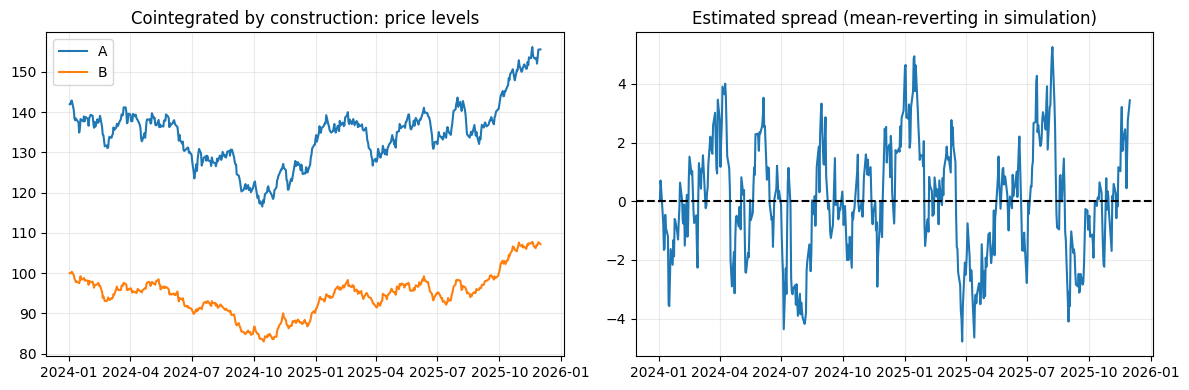

OLS beta (B units per A unit): 1.409
Example: long 1 share of A and short 1.409 shares of B


In [11]:
trend=100+np.cumsum(rng.normal(0,.6,N))
spread=np.zeros(N)
for t in range(1,N):spread[t]=.88*spread[t-1]+rng.normal(0,.85)
asset_b=trend
asset_a=7+1.35*asset_b+spread
beta_pair=ols_slope(asset_a,asset_b)
residual = asset_a-(np.mean(asset_a)-beta_pair*np.mean(asset_b))-beta_pair*asset_b
fig, ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(dates,asset_a,label='A');ax[0].plot(dates,asset_b,label='B');ax[0].legend();ax[0].set(title='Cointegrated by construction: price levels')
ax[1].plot(dates,residual);ax[1].axhline(0,color='black',ls='--');ax[1].set(title='Estimated spread (mean-reverting in simulation)')
plt.tight_layout();plt.show()
print('OLS beta (B units per A unit):',round(beta_pair,3))
print('Example: long 1 share of A and short',round(beta_pair,3),'shares of B')

## 9. Commodities: correlated cross-hedge

If the exact exposure has no liquid matching future (for example, regional jet-fuel costs hedged with crude futures), use a **cross-hedge**. A low correlation creates irreducible **basis risk**. Work with **daily monetary value changes per comparable unit** and then convert into contracts using the futures contract size.

Here we build jet-fuel exposure to a regional price and a crude-oil futures hedge. The sign of the business exposure matters: an airline facing *higher fuel costs* has a negative P&L when fuel prices rise and therefore generally needs a **long** oil futures hedge.

Cross-hedge: LONG 51.36 oil futures contracts (before rounding).
Jet / crude price-change correlation: 0.79
Commodity cross-hedge: unhedged daily vol=95,428.62, hedged daily vol=58,054.70, variance reduction=63.0%


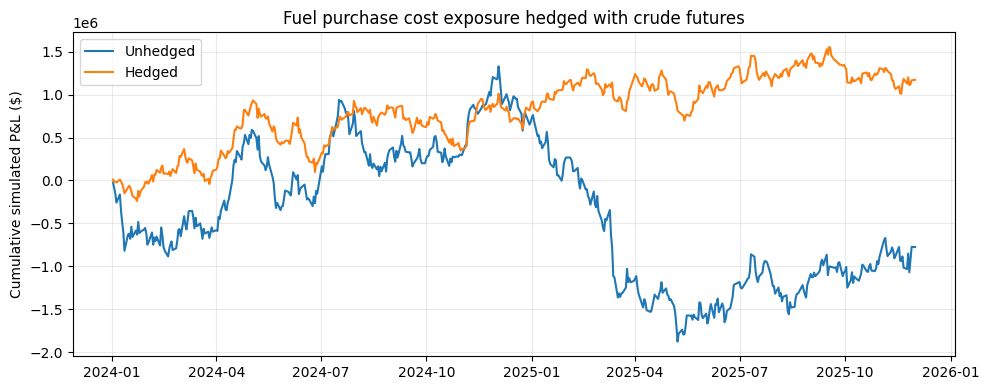

In [12]:
oil_change=rng.normal(0,1.5,N)    # $ / barrel
jet_change=.85*oil_change+rng.normal(0,1.0,N)
barrels_needed=60_000
crude_contract_bbl=1000
# exposure: future fuel purchase costs hurt when jet fuel rises
fuel_cost_pnl=-barrels_needed*jet_change
crude_contract_pnl=crude_contract_bbl*oil_change
q_crude=-ols_slope(fuel_cost_pnl,crude_contract_pnl)
hedged_fuel=fuel_cost_pnl+q_crude*crude_contract_pnl
print(f'Cross-hedge: LONG {q_crude:.2f} oil futures contracts (before rounding).')
print(f'Jet / crude price-change correlation: {np.corrcoef(jet_change,oil_change)[0,1]:.2f}')
report('Commodity cross-hedge',fuel_cost_pnl,hedged_fuel)
pnl_plot(dates,fuel_cost_pnl,hedged_fuel,'Fuel purchase cost exposure hedged with crude futures',ylabel='Cumulative simulated P&L ($)')

## 10. Multiple hedge instruments (multi-factor / multi-bond hedge)

When several bonds or futures are available, find a vector \(\mathbf q\) that minimises variance:

\[
\mathbf q^*=-\Sigma_{XX}^{-1}\operatorname{Cov}(\mathbf X,Y).
\]

In practice use a numerically stable **least-squares solver**, not an explicit inverse. A multivariate linear regression with intercept estimates all slopes jointly, taking correlation between hedges into account. Perfectly correlated hedge instruments make the estimation ill-conditioned; liquidity constraints, turnover costs and regularisation can be necessary.

OLS exposure sensitivities: [-7.985  4.968]
Hedge quantities q (positive=buy): [ 7.985 -4.968]
Two-factor hedge: unhedged daily vol=7,484.58, hedged daily vol=1,910.09, variance reduction=93.5%


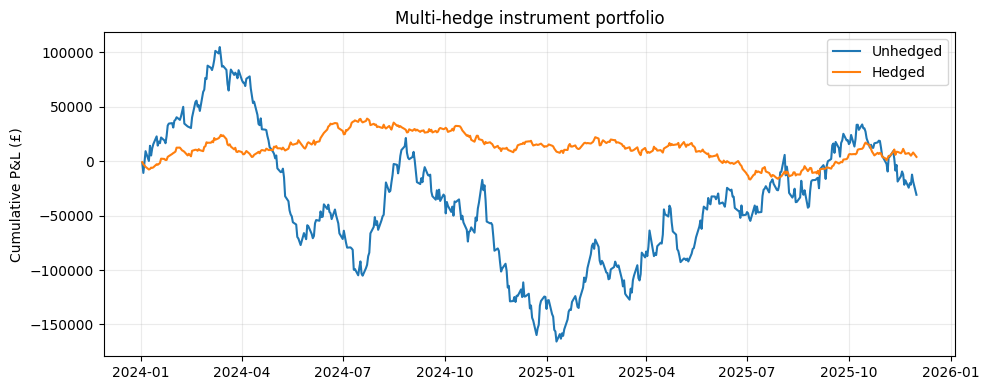

In [13]:
factor1=rng.normal(0,1,N);factor2=.35*factor1+rng.normal(0,1,N)
hedge_X=np.column_stack([800*factor1,1100*factor2])  # £/day per hedge unit
book_Y=-8*hedge_X[:,0]+5*hedge_X[:,1]+rng.normal(0,2000,N)
A=np.column_stack([np.ones(N),hedge_X])
coefs=np.linalg.lstsq(A,book_Y,rcond=None)[0]
q_multi=-coefs[1:]
hedged_multi=book_Y+hedge_X@q_multi
print('OLS exposure sensitivities:',coefs[1:].round(3))
print('Hedge quantities q (positive=buy):',q_multi.round(3))
report('Two-factor hedge',book_Y,hedged_multi)
pnl_plot(dates,book_Y,hedged_multi,'Multi-hedge instrument portfolio')

## 11. Practical workflow for EOD futures P&L + bond prices

1. **Define risk objective:** minimise historical P&L variance, neutralise parallel DV01, or neutralise the yield curve? The solutions need not agree.
2. **Build target P&L:** same-day end-to-end mark-to-market P&L for *stable* positions; identify unrelated realised/trading P&L and funding/FX effects.
3. **Construct hedge unit:** \(X_t=(B_t-B_{t-1})\times\mathrm{Face}/100\) for clean-price-only approximation; use full self-financing bond holding P&L when possible.
4. **Align time and units:** date, timezone/market close, currency, market conventions, price versus yield and sign.
5. **Estimate on training data only:** \(q=-\operatorname{Cov}(Y,X)/\operatorname{Var}(X)\); if possible compare with \(-DV01_p/DV01_b\).
6. **Convert into tradable face / contracts:** round sensible quantities, respect lots, liquidity, financing, short availability and transaction costs.
7. **Validate on unseen days:** compare daily P&L standard deviation, variance reduction, tail quantiles, drawdowns and stability over rolling windows.
8. **Monitor drift:** when positions, bond duration, volatility regime or correlation change, a previously fitted ratio may be wrong.

### Frequent beginner mistakes

- Comparing portfolio daily P&L with the **bond price level** rather than the day's **bond P&L**.
- Mixing return betas (dimensionless) and monetary P&L betas (units of hedge quantity).
- Ignoring bond quotes per **100 face** and futures contract multipliers.
- Forgetting the **negative** sign in the position (the OLS beta is an exposure sensitivity, not necessarily the trade size).
- Confusing a **hedging instrument's price direction** with its **DV01 sign**.
- Assuming all interest-rate maturities move in parallel.
- Measuring impressive performance in sample, then assuming it will persist out of sample.

## 12. Exercises — attempt before revealing the solutions below

**Exercise A (units):** A bond price quoted per £100 moves from 99.25 to 99.40. What is the mark-to-market P&L on £2m face, ignoring accrued interest?

**Exercise B (sign):** Your futures book daily P&L is *negatively* related to the daily P&L of £1m bond face. Should the statistical hedge be long or short the bond?

**Exercise C (variance):** If the in-sample correlation is 0.70, what is the theoretical maximum single-instrument variance reduction under the assumptions in §2?

**Exercise D (DV01):** A futures portfolio has +£12,000/bp and each £1m face bond has +£600/bp (gain for a 1bp yield fall). How many £1m face blocks are needed, and which direction?

**Exercise E (coding):** For the simulated EOD futures and bond dataset, use only the first 250 dates to estimate \(q\), test it on the remaining 250, and compare the observed variance reduction to the full-sample result. Why do results differ?

**Exercise F (conceptual):** Why might a portfolio/bond hedge that reduces 90% of historical daily variance still lose money during a sharp yield-curve twist?

**Exercise G (options):** You hold 30 long calls, each on 100 shares, with delta 0.4. How many shares should you short to be delta neutral? What causes the hedge to become stale?

In [14]:
# Exercise E: editable starter code
train_end = 250
# TODO: compute q using x_b[:train_end] and y_f[:train_end]
exercise_q = -ols_slope(y_f[:train_end], x_b[:train_end])
exercise_test_pnl = y_f[train_end:] + exercise_q*x_b[train_end:]
print('Exercise E estimated q:', round(exercise_q, 3))
report('Exercise E unseen evaluation',y_f[train_end:],exercise_test_pnl)

Exercise E estimated q: 14.068
Exercise E unseen evaluation: unhedged daily vol=10,609.66, hedged daily vol=4,031.97, variance reduction=85.6%


np.float64(0.8555784490730307)

### Worked exercise solutions

**A:** \((99.40-99.25)/100\times£2{,}000{,}000=+£3{,}000\).

**B:** **Long**, because the covariance is negative and \(q=-\operatorname{Cov}/\operatorname{Var}\) is positive.

**C:** \(0.7^2=0.49\), i.e. **49% variance reduction**, in sample under the simple regression assumptions.

**D:** \(q=-12{,}000/600=-20\): **short £20m face** of the bond.

**E:** Compare the result printed above with §4; coefficient estimates and realised covariance vary by sample and regime. Using data from the test set to determine the position would introduce look-ahead bias.

**F:** An aggregate covariance regression averages past moves; sharp non-parallel curve shifts and basis changes can generate unexpected losses.

**G:** Short \(30\times100\times0.4=1{,}200\) shares. Delta changes with underlying price, time to expiry, volatility and dividends; hedge shares therefore need rebalancing.

---

### Key formulas to remember

| Situation | Hedge position (long positive) |
|---|---|
| Daily P&L regression | \(q=-\mathrm{Cov}(Y,X)/\mathrm{Var}(X)\) |
| Correlation/volatility form | \(q=-\rho\sigma_Y/\sigma_X\) (when both series are monetary P&L per hedge unit) |
| Equity futures contracts | \(N=-\beta V_p/(F M)\) |
| Parallel DV01 | \(q=-DV01_p/DV01_{\mathrm{hedge\ unit}}\) |
| Long options | Shares held \(=-nM\Delta\) |
| Pairs spread | \(P_A-\beta P_B\) (requires validated stationarity / cointegration) |

**Bottom line:** For your **futures book EOD P&L vs bond EOD prices**, first obtain a **daily monetary P&L series for one standard bond position**. Then calculate the **negative OLS coefficient**, turn it into a real bond face amount, compare with DV01 hedge sizing, and verify on unseen data.